# GVH Diagonal Cubic — CHH-15
## Unrestricted Linearized ADM–Æther–Triad Constraint Symbol — scoped 1D FAST gate

**Scientific designation:** `EOM-GVH / NEW-HYPOTHESIS / LINEARIZED_1D_SYMBOL`. The historical title says "Unrestricted"; the *actual executable scope* is an **all-16-field, flat-background, plane-wave linearization with wavevector parallel to the distinguished x direction**. It is **not** full nonlinear 4D Dirac–Bergmann or strong-hyperbolicity proof.

**Four levels:** 1. candidate GVH extended action; 2. mathematical and Einstein–æther references; 3. executed symbolic/numeric constraints and dispersion; 4. precise scientific verdict.

**Frozen CHH rule:** composition CHH is a non-differential aggregation operator, and **does not intrinsically prescribe global EOM**. All derivatives below belong to the *separate, explicitly proposed* dynamical action `S12` or to mathematical auditing; none is a `CHH` derivative.

**Upstream exactly inspected:** executed CHH-12, CHH-13 and CHH-14 notebooks; frozen protocol v1.0. See SHA provenance in certificate. This notebook reproduces the action *directly* in the code; it does not silently import a precomputed dispersion polynomial.

## Niveau 1 — Action and exhaustive linear perturbation variables

Use the **candidate extension** (not derived from original unextended $S_{\rm cand}$):

$$S_{12}=\frac1{16\pi G_0}\int d^4x\sqrt{-g}\big[R+\mathcal L_u+\frac{\zeta_C}{2}\mathcal O_C+\mathcal L_{\rm rot}+\text{normalization constraints}\big].$$

$$\mathcal L_u=-c_1\nabla_\mu u_\nu\nabla^\mu u^\nu-c_2(\nabla\cdot u)^2-c_3\nabla_\mu u_\nu\nabla^\nu u^\mu+c_4 a_\mu a^\mu,$$
$$\mathcal O_C=\sum_{A=1}^3(e_A^\mu e_A^\nu\sigma_{\mu\nu})^2,\quad \mathcal L_{\rm rot}=\frac{\kappa_t}{4}(u^\mu\Omega_{\mu AB})^2-\frac{\kappa_s}{4}P^{\mu\nu}\Omega_{\mu AB}\Omega_{\nu AB}.$$

Signature $(-,+,+,+)$, sum over *ordered* $AB$; $\Omega_{\mu AB}=e_{A\nu}\nabla_\mu e_B^\nu$ and $P^{\mu\nu}=g^{\mu\nu}+u^\mu u^\nu$. Spin rotations are candidate physical degrees of freedom, **not silently gauged away**.

Linearize at $g_{\mu\nu}=\eta_{\mu\nu}$, $u^\mu=\delta^\mu_0$, $e_A^i=\delta_A^i$, using all sixteen independent fields:

$$q=(n,s_x,s_y,s_z,h_{xx},h_{xy},h_{xz},h_{yy},h_{yz},h_{zz},v_x,v_y,v_z,\chi_{12},\chi_{13},\chi_{23}).$$

Here $h_{00}=-2n$, $h_{0i}=s_i$, $h_{ij}$ is the spatial metric perturbation, and normalized $\delta u^0=-n$, $\delta u^i=v_i$. The triad is orthonormal to linear order, with $e_A^i=\delta_A^i-\frac12 h^i{}_A+\chi^i{}_A$ and $e_A^0=v_A+s_A$.

To probe a directional principal symbol only, take all fields as functions of $(t,x)$ and set $\partial_y=\partial_z=0$. No matter, curvature of background, spatially varying coefficients, or nonlinear constraints is included.

In [1]:
import sympy as s, time
T=time.time()
q=s.symbols('n sx sy sz hxx hxy hxz hyy hyz hzz vx vy vz chi12 chi13 chi23',real=True)
n,sx,sy,sz,hxx,hxy,hxz,hyy,hyz,hzz,vx,vy,vz,chi12,chi13,chi23=q
qd=s.symbols(' '.join('dt_'+str(v) for v in q),real=True); qx=s.symbols(' '.join('dx_'+str(v) for v in q),real=True)
Ds={q[i]:(qd[i],qx[i]) for i in range(16)}
def D(v,mu):return Ds[v][mu] if mu in (0,1) else s.S.Zero
h=s.Matrix([[-2*n,sx,sy,sz],[sx,hxx,hxy,hxz],[sy,hxy,hyy,hyz],[sz,hxz,hyz,hzz]])
dh=[h.applyfunc(lambda z:s.expand(sum(s.diff(z,v)*D(v,i) for v in q))) for i in range(4)]
eta=s.diag(-1,1,1,1)
du=s.Matrix([-n,vx+sx,vy+sy,vz+sz]);ddu=[du.applyfunc(lambda z:s.expand(sum(s.diff(z,v)*D(v,i) for v in q)) if z else 0) for i in range(4)]
Gamma0=lambda i,j:-(dh[i][j,0]+dh[j][i,0]-dh[0][i,j])/2
U=s.Matrix(4,4,lambda i,j: ddu[i][j]+Gamma0(i,j))
theta=sum(eta[i,i]*U[i,i] for i in range(4))
c1,c2,c3,c4,z,kt,ks=s.symbols('c1 c2 c3 c4 z kt ks',real=True)
Lu=-c1*sum(eta[i,i]*eta[j,j]*U[i,j]**2 for i in range(4) for j in range(4)) -c3*sum(eta[i,i]*eta[j,j]*U[i,j]*U[j,i] for i in range(4) for j in range(4))-c2*theta**2+c4*sum(U[0,j]**2 for j in range(1,4))
OC=sum((U[i,i]-theta/3)**2 for i in range(1,4))
chi={(1,2):chi12,(1,3):chi13,(2,3):chi23}
Om={(mu,A,B):D(chi[(A,B)],mu)+s.Rational(1,2)*(dh[B][A,mu]-dh[A][B,mu]) for mu in range(4) for A,B in chi}
Lrot=kt*s.Rational(1,2)*sum(Om[(0,A,B)]**2 for A,B in chi) -ks*s.Rational(1,2)*sum(Om[(mu,A,B)]**2 for mu in range(1,4) for A,B in chi)
# Fierz-Pauli EH with correct normalization half standard
Dtrace=[sum(eta[i,i]*dh[mu][i,i] for i in range(4)) for mu in range(4)]
Bup=[sum(eta[mu,mu]*eta[nu,nu]*dh[mu][mu,nu] for mu in range(4)) for nu in range(4)]
Leh=-s.Rational(1,4)*sum(eta[mu,mu]*sum(eta[i,i]*eta[j,j]*dh[mu][i,j]**2 for i in range(4) for j in range(4)) for mu in range(4)) +s.Rational(1,2)*sum(eta[nu,nu]*Bup[nu]**2 for nu in range(4))-s.Rational(1,2)*sum(Bup[nu]*Dtrace[nu] for nu in range(4))+s.Rational(1,4)*sum(eta[mu,mu]*Dtrace[mu]**2 for mu in range(4))
L=s.expand(Leh+Lu+z*OC/2+Lrot)

print('Fields:', len(q), 'quadratic derivative monomials:',len(s.Add.make_args(L)))


Fields: 16 quadratic derivative monomials: 113


## Niveau 2 — Independent geometric formulas and Hessians

At first order, with $\partial_\mu=\partial_t,\partial_x,0,0$:

$$\nabla_\mu u_\nu^{(1)}=\partial_\mu(\delta u_\nu)+\Gamma^0_{\mu\nu},\quad \delta u_\nu=(-n,v_x+s_x,v_y+s_y,v_z+s_z),$$
$$\Gamma^0_{\mu\nu}=-\tfrac12(\partial_\mu h_{\nu0}+\partial_\nu h_{\mu0}-\partial_0 h_{\mu\nu}),$$
$$\Omega_{\mu AB}^{(1)}=\partial_\mu\chi_{AB}+\tfrac12(\partial_Bh_{A\mu}-\partial_Ah_{B\mu}).$$

The Einstein–Hilbert quadratic density is the **half-normalized Fierz–Pauli form**, chosen so TT $h_{yy}=-h_{zz}=h_+$ contributes $\tfrac12(\dot h_+^2-h_{+,x}^2)$, matching CHH-14. The action contains no field-value potential at this order, so the principal system can be expressed using Hessians of first derivatives:

$$K_{ab}=\frac{\partial^2\mathcal L^{(2)}}{\partial\dot q_a\partial\dot q_b},\quad G_{ab}=\frac{\partial^2\mathcal L^{(2)}}{\partial q_{a,x}\partial q_{b,x}},\quad C_{ab}=\frac{\partial^2\mathcal L^{(2)}}{\partial\dot q_a\partial q_{b,x}},$$
$$P(\omega,k)=-\omega^2K+\omega k(C+C^T)-k^2G.$$

This is a **second-order Euler–Lagrange principal symbol**, not the first-order-in-time/space strongly hyperbolic reduction.

In [2]:
from collections import OrderedDict
from pathlib import Path
import json,hashlib,math
import numpy as np
from scipy.linalg import svdvals
import matplotlib.pyplot as plt
base_path=Path('/mnt/data'); checks=OrderedDict(); details={}
def gate(name,condition,evidence=None):
    ok=bool(condition)
    checks[name]={'passed':ok,'evidence':evidence}
    if not ok: raise AssertionError(f'{name}: {evidence}')
    print(('PASS ' if ok else 'FAIL ')+name)
K=s.hessian(L,qd);G=s.hessian(L,qx);C=s.Matrix(16,16,lambda i,j:s.diff(L,qd[i],qx[j]));
w,k=s.symbols('w k',real=True)
P=-w**2*K+w*k*(C+C.T)-k**2*G
# gauge vectors without i
z0=s.zeros(16,1);z0[q.index(n)]=w;z0[q.index(sx)]=k
z1=s.zeros(16,1);z1[q.index(sx)]=w;z1[q.index(hxx)]=-2*k;z1[q.index(vx)]=-w
z2=s.zeros(16,1);z2[q.index(sy)]=w;z2[q.index(hxy)]=-k;z2[q.index(vy)]=-w;z2[q.index(chi12)]=-k/2
z3=s.zeros(16,1);z3[q.index(sz)]=w;z3[q.index(hxz)]=-k;z3[q.index(vz)]=-w;z3[q.index(chi13)]=-k/2

gate('sixteen_fields_present',len(q)==16)
gate('aether_unit_norm_constraint_linear',s.expand(-2*(-n)-2*n)==0)
gate('u00_cov_derivative_zero',s.simplify(U[0,0])==0)
gate('u_i0_cov_derivative_zero',all(s.simplify(U[i,0])==0 for i in range(1,4)))
gate('lapse_absent_from_velocity_hessian',all(K[0,j]==0 for j in range(16)))
gate('time_hessian_symmetric',K==K.T)
gate('space_hessian_symmetric',G==G.T)
gate('symbol_matrix_symmetric',P==P.T)
for j,ga in enumerate([z0,z1,z2,z3]):
    res=[s.factor(v) for v in P*ga]
    gate(f'linearized_full_gauge_identity_{j}',all(v==0 for v in res), 'analytic in couplings, omega, k')
print('First-order aether covariant-gradient tensor:')
s.pprint(U)


PASS sixteen_fields_present
PASS aether_unit_norm_constraint_linear
PASS u00_cov_derivative_zero
PASS u_i0_cov_derivative_zero
PASS lapse_absent_from_velocity_hessian
PASS time_hessian_symmetric
PASS space_hessian_symmetric
PASS symbol_matrix_symmetric
PASS linearized_full_gauge_identity_0
PASS linearized_full_gauge_identity_1
PASS linearized_full_gauge_identity_2
PASS linearized_full_gauge_identity_3
First-order aether covariant-gradient tensor:
⎡0  dtₛₓ + dtᵥₓ + dxₙ      dt_sy + dt_vy           dt_sz + dt_vz     ⎤
⎢                                                                    ⎥
⎢     dtₕₓₓ            dt_hxy   dx_sy          dt_hxz   dx_sz        ⎥
⎢0    ───── + dxᵥₓ     ────── + ───── + dx_vy  ────── + ───── + dx_vz⎥
⎢       2                2        2              2        2          ⎥
⎢                                                                    ⎥
⎢    dt_hxy   dx_sy            dt_hyy                  dt_hyz        ⎥
⎢0   ────── - ─────            ──────               

## Niveau 3 — Generic constrained-rank and gauge-fixing gate

The four exact null directions of $P$ encode linearized spacetime diffeomorphisms. They are distinct from the candidate triad's **physical** rotations.

For a nonzero frequency $\omega$, the four gauge conditions $n=s_x=s_y=s_z=0$ are reachable (the gauge-transformation determinant is proportional to $\omega^4$). This choice is **singular for $\omega=0$**: any zero-frequency factor in the gauge-fixed determinant must be kept as an unresolved constraint/gauge artifact, not automatically classified as a physical instantaneous mode.

Choose **prescribed rational**, not fitted, demonstration couplings:
$$c_1=2/5,\quad c_2=1/10,\quad c_3=-1/10,\quad c_4=1/10,\quad\zeta_C=1/5,\quad\kappa_t=7/5,\quad\kappa_s=7/10.$$
These values are *not* empirical calibration, have not passed observational constraints, and are used only to test algebraic coherence.

The expected velocity Hessian rank is 12: $n$ has no time derivative and the three differences $(s_i-v_i)$ are null velocity directions. This fact is **only a primary degeneracy indicator**, not a completed canonical Dirac classification.

In [3]:
pars={c1:s.Rational(2,5),c2:s.Rational(1,10),c3:-s.Rational(1,10),c4:s.Rational(1,10),z:s.Rational(1,5),kt:s.Rational(7,5),ks:s.Rational(7,10)}
Kn=K.subs(pars)
gate('numeric_rational_hessian_rank_12',Kn.rank()==12,int(Kn.rank()))
gate('numeric_primary_kernel_lapse',Kn*s.eye(16)[:,0]==s.zeros(16,1))
for i,(j,sname,vname) in enumerate([(1,'sx','vx'),(2,'sy','vy'),(3,'sz','vz')]):
    v=s.zeros(16,1);v[j]=1;v[10+i]=-1
    gate(f'primary_velocity_kernel_shift_minus_aether_{sname}',Kn*v==s.zeros(16,1))
gauge_reachability=s.det(s.Matrix([[w,0,0,0],[k,w,0,0],[0,0,w,0],[0,0,0,w]]))
gate('temporal_spatial_gauge_reachable_nonzero_omega',s.factor(gauge_reachability)==w**4)
Pnum=P.subs(pars).subs(k,1)
gate('generic_full_symbol_rank_12',Pnum.subs(w,s.Rational(3,2)).rank()==12)
keep=list(range(4,16));Pfix=Pnum.extract(keep,keep)
gate('nonzero_frequency_fixed_symbol_rank_12',Pfix.subs(w,s.Rational(3,2)).rank()==12)
print('Gauge reachability det:',gauge_reachability)


PASS numeric_rational_hessian_rank_12
PASS numeric_primary_kernel_lapse
PASS primary_velocity_kernel_shift_minus_aether_sx
PASS primary_velocity_kernel_shift_minus_aether_sy
PASS primary_velocity_kernel_shift_minus_aether_sz
PASS temporal_spatial_gauge_reachable_nonzero_omega
PASS generic_full_symbol_rank_12
PASS nonzero_frequency_fixed_symbol_rank_12
Gauge reachability det: w**4


## Niveau 3 — Exact sector factorization, nonzero characteristic candidates

For the chosen propagation axis and couplings, the gauge-fixed 12×12 symbol splits into one 4×4 scalar/plus block, **two** identical 3×3 vector-plus-spin blocks, one cross tensor, and one axial spin block. Factor each determinant separately and verify the product equals the complete determinant. Nonzero roots are **candidate directional squared phase speeds**, not physical mode counts certified by the full nonlinear constraints.

The polynomial contains $\omega^8$ even after fixing $n=s_i=0$. Because this gauge is singular at $\omega=0$, it would be incorrect to proclaim four propagating zero-speed modes from that factor. Full first-order hyperbolicity and all constraint propagation remain open.

In [4]:
groups=OrderedDict([
  ('scalar_plus',[4,7,9,10]),
  ('vector_y',[5,11,13]),
  ('vector_z',[6,12,14]),
  ('tensor_cross',[8]),
  ('spin_axial',[15])
])
for name,ids in groups.items():
    off=[(i,j) for i in ids for other,js in groups.items() if other!=name for j in js if s.factor(Pnum[i,j])!=0]
    gate('block_decoupled_'+name,len(off)==0,off[:3])
sect_dets={name:s.factor(Pnum.extract(ids,ids).det(method='domain-ge')) for name,ids in groups.items()}
for n,v in sect_dets.items(): print(n,':',v)
total_det=s.factor(Pfix.det(method='domain-ge'))
gate('complete_12x12_determinant_sector_product',s.factor(total_det-s.prod(sect_dets.values()))==0)
expect_det=-s.Rational(343,9600000000000)*w**8*(2*w**2-1)*(14*w**2-27)*(16*w**2-27)*(624*w**2-335)*(140*w**4-235*w**2+93)**2
gate('independent_explicit_determinant_factorization',s.simplify(total_det-expect_det)==0)
y=s.symbols('y',real=True)
branches=OrderedDict([
  ('spin_axial',s.Rational(1,2)),
  ('scalar',s.Rational(335,624)),
  ('vector_low',s.Rational(47,56)-s.sqrt(3145)/280),
  ('vector_high',s.Rational(47,56)+s.sqrt(3145)/280),
  ('tensor_plus',s.Rational(27,16)),
  ('tensor_cross',s.Rational(27,14)),
])
for name,yval in branches.items():gate('squared_phase_speed_positive_'+name,float(yval)>0,str(yval))
roots=[]
for name,yval in branches.items():
    mult=2 if name.startswith('vector_') else 1
    roots.append({'sector':name,'y_exact':str(yval),'speed_squared':float(yval),'speed_c':math.sqrt(float(yval)),'multiplicity_in_1D_factor':mult})
gate('nonzero_phase_branches_form_eight_candidates',sum(r['multiplicity_in_1D_factor'] for r in roots)==8)
for name,yval in branches.items():
    omega_val=math.sqrt(float(yval))
    m=np.asarray(Pfix.subs(w,omega_val),float)
    sv=np.linalg.svd(m,compute_uv=False)
    nul=int(np.sum(sv<1e-7*max(sv)))
    target=2 if name.startswith('vector_') else 1
    gate('numerical_nullity_at_'+name,nul==target,{'nullity':nul,'expected':target,'smallest_sv':float(sv[-1])})
print('Factorized full determinant:');s.pprint(total_det)


PASS block_decoupled_scalar_plus
PASS block_decoupled_vector_y
PASS block_decoupled_vector_z
PASS block_decoupled_tensor_cross
PASS block_decoupled_spin_axial
scalar_plus : -w**4*(16*w**2 - 27)*(624*w**2 - 335)/48000
vector_y : -7*w**2*(140*w**4 - 235*w**2 + 93)/1000
vector_z : -7*w**2*(140*w**4 - 235*w**2 + 93)/1000
tensor_cross : -(14*w**2 - 27)/20
spin_axial : -7*(2*w**2 - 1)/10
PASS complete_12x12_determinant_sector_product
PASS independent_explicit_determinant_factorization
PASS squared_phase_speed_positive_spin_axial
PASS squared_phase_speed_positive_scalar
PASS squared_phase_speed_positive_vector_low
PASS squared_phase_speed_positive_vector_high
PASS squared_phase_speed_positive_tensor_plus
PASS squared_phase_speed_positive_tensor_cross
PASS nonzero_phase_branches_form_eight_candidates
PASS numerical_nullity_at_spin_axial
PASS numerical_nullity_at_scalar
PASS numerical_nullity_at_vector_low
PASS numerical_nullity_at_vector_high
PASS numerical_nullity_at_tensor_plus
PASS numerica

## Niveau 2 — Physical reference comparison: unextended Einstein–æther

The known linearized Einstein–æther spin-$2$, spin-$1$, spin-$0$ squared speeds in the standard conventions are:

$$s_2^2=\frac1{1-c_{13}},\quad s_1^2=\frac{2c_1-c_1^2+c_3^2}{2c_{14}(1-c_{13})},\quad s_0^2=\frac{c_{123}(2-c_{14})}{c_{14}(1-c_{13})(2+c_{13}+3c_2)}.$$

Here $c_{13}=c_1+c_3$, $c_{14}=c_1+c_4$, $c_{123}=c_1+c_2+c_3$. **This notebook does not assume these as its modified-theory outcomes.** Instead we independently verify that, after setting the **new terms** $\zeta_C=\kappa_t=\kappa_s=0$ and removing the now-auxiliary rotations, the derived 2×2 vector and 4×4 scalar block determinants vanish at the literature speeds. This is a stringent GR/æther reduction check and must not be presented as new physics.

Sources: Jacobson & Mattingly, *Einstein-aether waves*, Phys. Rev. D 70, 024003 (2004), https://doi.org/10.1103/PhysRevD.70.024003. The spinning triad action has antecedents in Christopher Kohler, *Gravity with a Dynamical Spinning Aether* (2021), https://arxiv.org/abs/2109.03700.

In [5]:
EA={z:0,kt:0,ks:0,k:1}
EA_s2=1/(1-c1-c3)
EA_s1=(2*c1-c1**2+c3**2)/(2*(c1+c4)*(1-c1-c3))
EA_s0=(c1+c2+c3)*(2-c1-c4)/((c1+c4)*(1-c1-c3)*(2+c1+c3+3*c2))
EA_t=s.factor(P.extract([8],[8]).subs(EA).det())
EA_v=s.factor(P.extract([5,11],[5,11]).subs(EA).det())
EA_s=s.factor(P.extract([4,7,9,10],[4,7,9,10]).subs(EA).det(method='domain-ge'))
for label,det,root in [('spin2',EA_t,EA_s2),('spin1',EA_v,EA_s1),('spin0',EA_s,EA_s0)]:
    residual=s.factor(det.subs(w**2,root))
    gate('unextended_ae_'+label+'_known_speed_root',residual==0)
gate('ae_tensor_GR_limit',s.factor(EA_t.subs({c1:0,c2:0,c3:0,c4:0})-(1-w**2))==0)
EA_num={**pars,z:0,kt:0,ks:0}
gate('EA_sample_spin2_10_over_7',s.factor(EA_s2.subs(EA_num)-s.Rational(10,7))==0)
gate('EA_sample_spin1_13_over_14',s.factor(EA_s1.subs(EA_num)-s.Rational(13,14))==0)
gate('EA_sample_spin0_60_over_91',s.factor(EA_s0.subs(EA_num)-s.Rational(60,91))==0)
print('Unextended EA speed^2:',{'spin2':EA_s2.subs(EA_num),'spin1':EA_s1.subs(EA_num),'spin0':EA_s0.subs(EA_num)})


PASS unextended_ae_spin2_known_speed_root
PASS unextended_ae_spin1_known_speed_root


PASS unextended_ae_spin0_known_speed_root
PASS ae_tensor_GR_limit
PASS EA_sample_spin2_10_over_7
PASS EA_sample_spin1_13_over_14
PASS EA_sample_spin0_60_over_91
Unextended EA speed^2: {'spin2': 10/7, 'spin1': 13/14, 'spin0': 60/91}


## Niveau 3 — Reproducibility, no astrophysical fitting

Produce the numeric dispersion plot only from exact rational sample couplings and preserve positive/negative verdicts. **No new Solar System, galaxy, particle or ALMA prediction** is authorized from this toy background. A real planet/particle test requires source-coupled solutions, boundary conditions and independently fixed SI scales. The four-gauge-identity plus rank test is a genuine improvement over CHH-14, but **a 1D directional wave gate is not a full-4D non-linear Dirac analysis**.

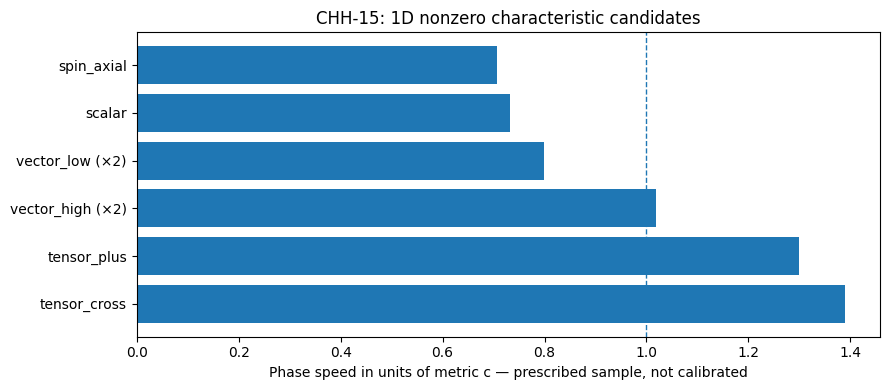

PASS plot_created


In [6]:
fig,ax=plt.subplots(figsize=(9,4))
labels=[r['sector']+(' (×2)' if r['multiplicity_in_1D_factor']==2 else '') for r in roots]
speeds=[r['speed_c'] for r in roots]
ax.barh(labels,speeds)
ax.axvline(1,ls='--',lw=1)
ax.set(xlabel='Phase speed in units of metric c — prescribed sample, not calibrated',title='CHH-15: 1D nonzero characteristic candidates')
ax.invert_yaxis();fig.tight_layout()
plot_path=base_path/'GVH_CHH_15_Directional_Principal_Speeds_FAST.png';fig.savefig(plot_path,dpi=145);plt.show()
gate('plot_created',plot_path.exists())


## Niveau 4 — Scientific verdict and open locks

**Supported:**

1. The 16-field quadratic derivative action of the **postulated** metric+æther+triad extension was explicitly constructed on the flat background for $(t,x)$ dependence.
2. Four spacetime-diffeomorphism gauge vectors exactly annihilate the derived full $16\times16$ symbol for arbitrary couplings $c_1,c_2,c_3,c_4,\zeta_C,\kappa_t,\kappa_s$.
3. At chosen rational sample couplings the time-derivative Hessian rank is 12. This is **not** a complete first-/second-class constraint count.
4. For $\omega\neq0$, a reachable gauge yields exact sector factorization and **eight** directional nonzero frequency candidates (counting degeneracy). The physicality of every candidate remains conditional on constraints, energy and strong hyperbolicity.
5. In the unextended Einstein–æther limit, the canonical known spin-2, spin-1 and spin-0 squared-speed formulas are recovered.

**Not supported:** no full $3+1$ Dirac closure, no global (all wave directions/backgrounds) hyperbolicity, no nonlinear solution with source, no ghost-free proof, no novelty compared with spinning-æther prior art, no direct solar/galactic/particle prediction. The $\omega=0$ determinant factor is **not classified**. No empirical validation.

**Next physically necessary gate:** `GVH_CHH_16_All_Direction_First_Order_Constraint_Propagation_and_Kinetic_Energy_Gate_FAST` to analyze generic directions relative to the triad, actual first-order principal matrix, constraint propagation and canonical energies **before interpreting high phase speeds as physical**. Parallel thread: derive sourced metric+vector+triad solutions and boundary conditions to unlock a Newton/GR/GVH residual comparison.

**Formal decision:** `PASS_16_FIELD_LINEAR_1D_GAUGE_AND_EA_LIMIT__FULL_4D_DIRAC_HYPERBOLICITY_AND_OBSERVATIONAL_LOCKS_OPEN`.

In [7]:
assert all(d['passed'] for d in checks.values())
up=base_path/'chh15_upstream'
upstream=[]
for n in ['GVH_CHH_12_Physical_Triad_Dynamics_or_Nonredundant_Operator_Candidate_Gate_FAST_EXECUTED.ipynb',
          'GVH_CHH_13_Full_Coupled_Constraint_and_Spinning_Aether_Equivalence_Gate_FAST_EXECUTED.ipynb',
          'GVH_CHH_14_Full_Metric_Spin_Principal_Symbol_and_Dirac_Constraints_GATE_FAST_EXECUTED.ipynb',
          'GVH_CHH_Protocole_Fige_CHH_Non_Derivation_ROOT22_v1_2026-11-18.md']:
    f=up/n
    upstream.append({'filename':n,'sha256':hashlib.sha256(f.read_bytes()).hexdigest() if f.exists() else None})
result={'notebook':'GVH_CHH_15_Unrestricted_Linearized_ADM_Aether_Triad_Constraint_Symbol_Gate_FAST',
        'version_date':'2026-11-19',
        'status':'PASS_16_FIELD_LINEAR_1D_GAUGE_AND_EA_LIMIT__FULL_4D_DIRAC_HYPERBOLICITY_AND_OBSERVATIONAL_LOCKS_OPEN',
        'scientific_class':'NEW_HYPOTHESIS_NOT_NEW_PHYSICAL_LAW',
        'scope':{'background':'Minkowski','dependence':'t,x','fields':len(q),'gauge_directions':4,'velocity_hessian_rank':int(Kn.rank()),
                 'metric_dynamics':'quadratic Fierz-Pauli plus aether and spin terms','all_3D_wave_directions':False,
                 'full_3plus1_Dirac_count':False,'proof_of_ghost_freedom':False,'strong_hyperbolicity_proved':False},
        'sample_couplings':{str(k):str(v) for k,v in pars.items()},
        'exact_fixed_gauge_determinant':str(total_det),'nonzero_directional_branches':roots,
        'EA_limit_speed_squared':{lab:str(expr.subs(EA_num)) for lab,expr in [('spin2',EA_s2),('spin1',EA_s1),('spin0',EA_s0)]},
        'zero_frequency_w8_unclassified':True,
        'CHH_has_intrinsic_derivative':False,'new_GVH_physics_validated':False,'solar_comparison_predicted':False,
        'upstream_sha256':upstream,
        'tests':checks,'checks_total':len(checks),'checks_passed':sum(d['passed'] for d in checks.values())}
resfile=base_path/'GVH_CHH_15_Unrestricted_Linearized_ADM_Aether_Triad_Constraint_Symbol_Gate_FAST_results.json'
resfile.write_text(json.dumps(result,indent=2,ensure_ascii=False),encoding='utf-8')
print('Certificate',resfile,'tests=',result['checks_total'],'PASS=',result['checks_passed'])


Certificate /mnt/data/GVH_CHH_15_Unrestricted_Linearized_ADM_Aether_Triad_Constraint_Symbol_Gate_FAST_results.json tests= 48 PASS= 48
